---
numbering: false
---

# 4.5: LU factorization for all matrices

So far, we've focused on finding LU factorizations of square matrices. But this LU approach extends to every matrix, regardless of its shape or whether the system has a unique solution.

---

## A factorization for every matrix

:::{important} Theorem: LU factorization
Every $n\times d$ matrix $A$ has a factorization

$$PA=LU,$$

where:

- $P$ is an $n\times n$ permutation matrix.
- $L$ is an $n\times n$ lower triangular matrix with ones on its diagonal.
- $U$ is an $n\times d$ matrix in **row echelon form**, which we define below.
:::

Multiplying by $P$ reorders the rows. When no row swaps are needed, we can take $P=I$ and write $A=LU$.

The factor $L$ is always square, and $U$ has the same shape as $A$:

$$(n\times d)=(n\times n)(n\times d).$$

The role of $U$ is to give us a system that we can solve from the bottom up. For a general matrix, the useful pattern is a **staircase**: the first nonzero entries move to the right as we move down the rows, and any zero rows come last. This is row echelon form. It allows us to use the same approach for square and non-square matrices.

As before, we will find the factors by multiplying and matching entries. [Chapter 4.6](04-06.ipynb) gives an optional interpretation: $U$ is the result of using row operations to create echelon form, while $L$ records the multiples used in those operations and $P$ records the row swaps.

---

## Row echelon form

:::{note} Definition: Row echelon form
A matrix is in **row echelon form** if:

1.  All zero rows come after all nonzero rows.

2.  The first nonzero entry of each nonzero row lies strictly to the right of the first nonzero entry in the preceding row.

The first nonzero entry in a nonzero row is called a **pivot**; its column is a **pivot column**. Pivots need not equal $1$.
:::

The pivot positions form a staircase. Everything to the left of a row's pivot is zero, and everything below a pivot is zero. A step can skip columns; it need not follow the main diagonal.

In the picture below, each blue $p$ is a nonzero pivot. Each $*$ can be any number, including zero. The orange staircase separates these entries from the required zeros.

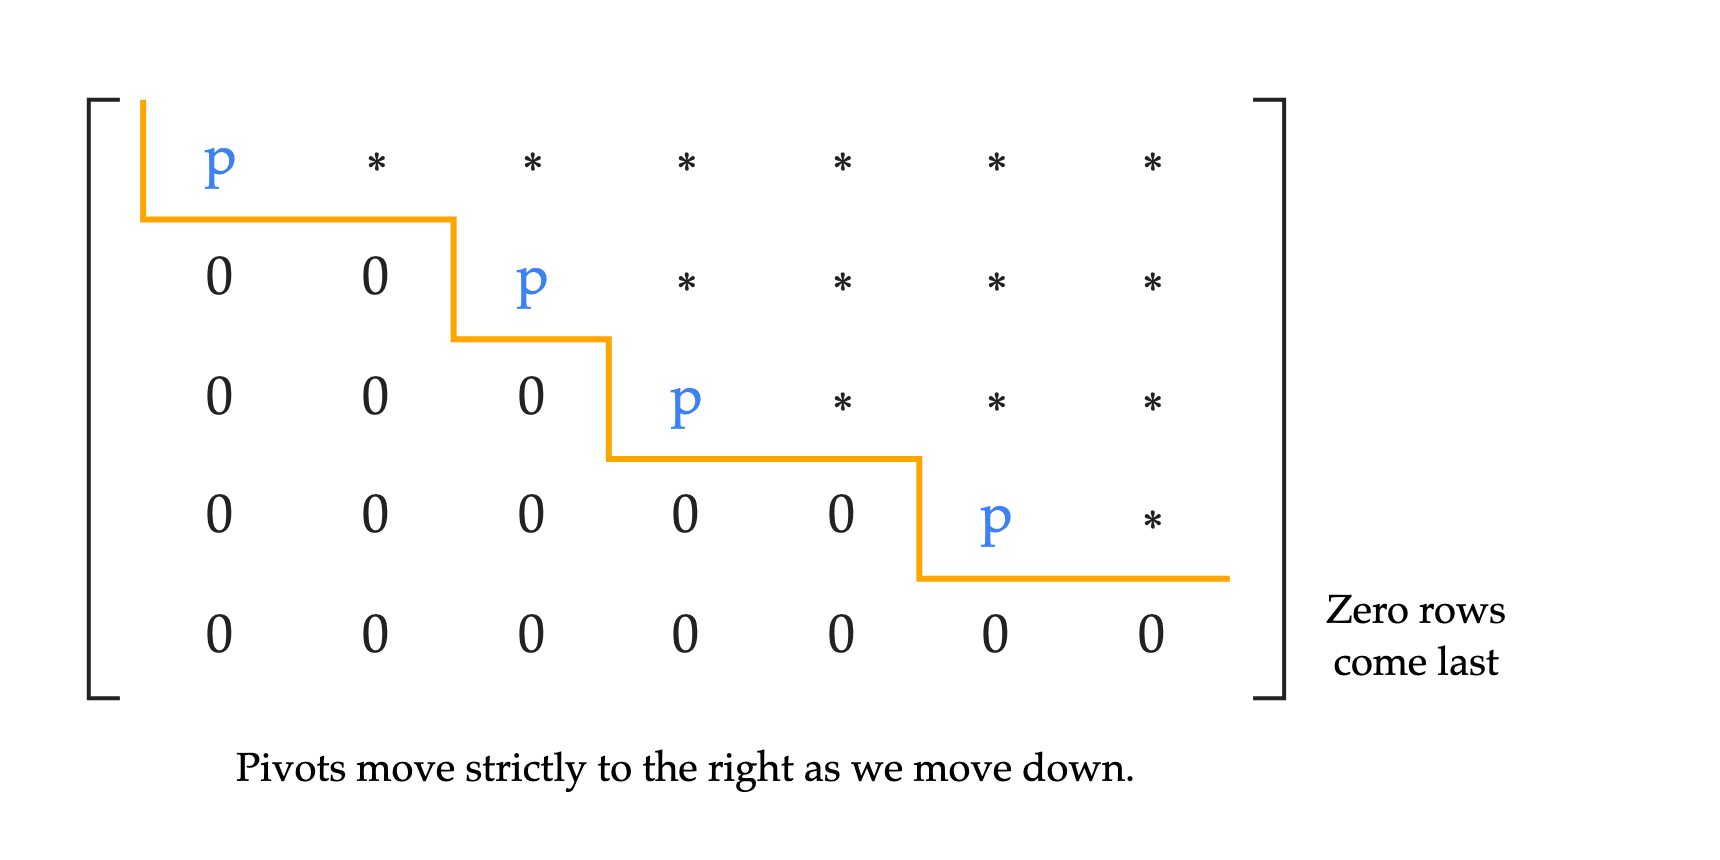

In [1]:
import plotly.graph_objects as go
from IPython.display import Image, display

pivot_columns = [1, 3, 4, 6]
fig = go.Figure()
for row in range(1, 6):
    pivot = pivot_columns[row - 1] if row <= 4 else 8
    for col in range(1, 8):
        value = "0" if col < pivot else ("p" if col == pivot else "∗")
        color = "#3d81f6" if col == pivot else "#222222"
        fig.add_annotation(x=col, y=row, text=value, showarrow=False,
                           font=dict(size=27, color=color))

# Follow the boundary below each pivot row, then step down before the next pivot.
fig.add_trace(go.Scatter(
    x=[0.5, 0.5, 2.5, 2.5, 3.5, 3.5, 5.5, 5.5, 7.5],
    y=[0.5, 1.5, 1.5, 2.5, 2.5, 3.5, 3.5, 4.5, 4.5],
    mode="lines", line=dict(color="orange", width=3), hoverinfo="skip"))
for x, inner in [(0.15, 0.35), (7.85, 7.65)]:
    fig.add_trace(go.Scatter(x=[inner, x, x, inner], y=[0.5, 0.5, 5.5, 5.5],
                            mode="lines", line=dict(color="#222222", width=2),
                            hoverinfo="skip"))
fig.add_annotation(x=8.1, y=5, text="Zero rows<br>come last", xanchor="left",
                   showarrow=False, font=dict(size=20))
fig.add_annotation(x=4, y=6.1, text="Pivots move strictly to the right as we move down.",
                   showarrow=False, font=dict(size=20))
fig.update_layout(width=860, height=430, margin=dict(l=25, r=20, t=20, b=15),
                  showlegend=False, paper_bgcolor="white", plot_bgcolor="white",
                  font=dict(family="Palatino", color="black"),
                  xaxis=dict(range=[-0.1, 10.4], visible=False, fixedrange=True),
                  yaxis=dict(range=[6.6, 0], visible=False, fixedrange=True))
png = fig.to_image(format="png", scale=2)
display(Image(data=png, width=860, alt="An echelon matrix with pivots in columns 1, 3, 4, and 6, an orange staircase below the pivots, and a final zero row."))


For example, each of these matrices is in row echelon form: 

$$\begin{bmatrix}\textcolor{#3d81f6}{\text{\textcircled{2}}}&1&-3\\0&\textcolor{#3d81f6}{\text{\textcircled{4}}}&2\\0&0&0\end{bmatrix},\qquad
\begin{bmatrix}\textcolor{#3d81f6}{\text{\textcircled{1}}}&2&-1\\0&0&\textcolor{#3d81f6}{\text{\textcircled{2}}}\\0&0&0\end{bmatrix},\qquad
\begin{bmatrix}\textcolor{#3d81f6}{\text{\textcircled{1}}}&2&-1&1\\0&0&\textcolor{#3d81f6}{\text{\textcircled{1}}}&2\end{bmatrix}.$$

 The first has pivots in columns $1$ and $2$. The other two have pivots in columns $1$ and $3$: column $2$ is skipped. In particular, **a pivot need not lie on the main diagonal**.

By contrast, 

$$\begin{bmatrix}1&2&-1\\0&0&2\\0&0&3\end{bmatrix}$$

 is upper triangular but is not in row echelon form: the last two rows begin in the same column. For general linear systems, echelon form gives more useful information than triangular shape alone.

### Recognizing row echelon form

::::{tip} Activity 1

For each matrix, decide whether it is in row echelon form. If it is, identify its pivots. If it is not, explain which requirement fails.

**a)** 

$$\begin{bmatrix}3&-1&2\\0&2&5\\0&0&-4\end{bmatrix}$$

**b)** 

$$\begin{bmatrix}1&2&0\\0&0&0\\0&0&3\end{bmatrix}$$

**c)** 

$$\begin{bmatrix}0&2&-1&4\\0&0&0&-3\end{bmatrix}$$

**d)** 

$$\begin{bmatrix}2&1&0\\0&0&4\\0&0&-2\end{bmatrix}$$

**e)** 

$$\begin{bmatrix}1&-2\\0&3\\0&0\end{bmatrix}$$

**f)** 

$$\begin{bmatrix}0&2&1\\3&0&-1\end{bmatrix}$$

**g)** 

$$\begin{bmatrix}0&0&0\\0&0&0\end{bmatrix}$$

**h)** 

$$\begin{bmatrix}1&2&-1\\2&0&3\\0&0&0\end{bmatrix}$$

:::{tip} Solution
:class: dropdown

**a)** **Yes.** The pivots occur in columns $1,2,3$: 

$$\begin{bmatrix}\boxed{3}&-1&2\\0&\boxed{2}&5\\0&0&\boxed{-4}\end{bmatrix}.$$

**b)** **No.** The zero second row occurs above the nonzero third row.

**c)** **Yes.** A zero first column is allowed. The pivots occur in columns $2,4$: 

$$\begin{bmatrix}0&\boxed{2}&-1&4\\0&0&0&\boxed{-3}\end{bmatrix}.$$

**d)** **No.** The first nonzero entries of the second and third rows are both in column $3$. The pivot positions must move strictly to the right.

**e)** **Yes.** The pivots occur in columns $1,2$, and the zero row is at the bottom: 

$$\begin{bmatrix}\boxed{1}&-2\\0&\boxed{3}\\0&0\end{bmatrix}.$$

**f)** **No.** The first nonzero entry moves from column $2$ in the first row to column $1$ in the second row. It moves left rather than right.

**g)** **Yes.** The zero matrix is in row echelon form. It has no pivots.

**h)** **No.** The first two rows both have their first nonzero entry in column $1$.
:::
::::

---

## Solving systems using LU

### Consistency and free variables

Suppose $PA=LU$. The system $A\vec x=\vec b$ is equivalent to 

$$LU\vec x=P\vec b.$$

:::{important} Solving with an LU factorization
Set $\vec y=U\vec x$. We solve in two stages: 

$$\boxed{\text{First solve }L\vec y=P\vec b,\qquad
\text{then solve }U\vec x=\vec y.}$$
:::

The first system always has a unique solution: $L$ is lower triangular with diagonal entries $1$. Forward substitution determines every entry of $\vec y$.

The second system may have no solution, one solution, or infinitely many solutions. The echelon form of $U$ tells us which possibility occurs.

:::{attention} Check consistency first
Every zero row of $U$ gives an equation $0=y_i$. If any such $y_i$ is nonzero, the system is inconsistent: there is no solution.
:::

**Separate the variables.** Keep the variables in pivot columns on the left and move the other variables to the right. For example, 

$$\begin{aligned}
x_1+2x_2-x_3&=3,\\
2x_3&=4
\end{aligned}
\quad\Longleftrightarrow\quad
\underbrace{\begin{bmatrix}1&-1\\0&2\end{bmatrix}}_{\text{upper triangular}}
\begin{bmatrix}x_1\\x_3\end{bmatrix}
=\begin{bmatrix}3-2x_2\\4\end{bmatrix}.$$

 The coefficient matrix on the left is upper triangular with **nonzero diagonal entries**. Thus, for each choice of $x_2$, we can solve uniquely for $x_1$ and $x_3$ by back substitution: $x_3=2$ and $x_1=5-2x_2$.

:::{note} Definition: Free and pivot variables
The variables moved to the right are called **free variables**, because we can choose their values arbitrarily. The variables kept on the left are called **pivot variables**. Here $x_2$ is free, while $x_1$ and $x_3$ are pivot variables.
:::

For any consistent echelon system, after omitting zero equations, this separation leaves a square upper triangular coefficient matrix with nonzero diagonal entries. Each choice of the free variables therefore determines the pivot variables uniquely.

### Counting pivots and free variables

After solving $L\vec y=P\vec b$, we can read the number of free variables from the pivots of $U$.

:::{important} Theorem: Solutions of an echelon system
Suppose $U$ has $r$ pivots. Its last $n-r$ rows are zero. Then 

$$A\vec x=\vec b\text{ is consistent}
\quad\Longleftrightarrow\quad
 y_{r+1}=\cdots=y_n=0.$$

 When it is consistent, it has exactly $d-r$ free variables. In particular:

-   If $r=d$, there is exactly one solution.

-   If $r<d$, there are infinitely many solutions over $\mathbb R$.

:::

For a fixed permutation matrix $P$ for which $PA=LU$, the echelon factor $U$ is unique. If $U$ has $r$ nonzero rows (equivalently, $r$ pivots), then the first $r$ columns of $L$ are also unique. Finally, the number $r$ does not depend on the choice of $P$, $L$, or $U$.

:::{note} Definition: Rank
The number $r$ of pivots in $U$, where $PA=LU$, is called the **rank** of $A$.
:::

Rank is a very important **invariant** of a matrix: it is a property of $A$ itself, independent of the factors used to compute it. For now, we define it as the number of pivots in $U$. Later, we will see equivalent, more conceptual ways to think about rank.

If there are no zero rows, the consistency condition imposes no restrictions. If there are no pivots, every variable is free whenever the system is consistent.

We will now see a number of examples.


---

## Examples

### Example 1: No solution

Consider 

$$\begin{bmatrix}2&-1&3\\0&0&2\\0&0&0\end{bmatrix}
\begin{bmatrix}x_1\\x_2\\x_3\end{bmatrix}
=\begin{bmatrix}5\\6\\4\end{bmatrix}.$$

 Written out, these equations are 

$$2x_1-x_2+3x_3=5,\qquad 2x_3=6,\qquad 0=4.$$

 The last equation is impossible, so the solution set is empty. There is no need to solve the preceding equations. A nonpivot column does not rescue an inconsistent system.

### Example 2: Solution set is a line

Now consider 

$$\begin{bmatrix}1&2&-1\\0&0&2\\0&0&0\end{bmatrix}
\begin{bmatrix}x_1\\x_2\\x_3\end{bmatrix}
=\begin{bmatrix}3\\4\\0\end{bmatrix}.$$

 The equations are 

$$x_1+2x_2-x_3=3,\qquad 2x_3=4,\qquad 0=0.$$

 The zero row causes no contradiction. The second equation gives $x_3=2$. Column $2$ has no pivot, so choose $x_2=t$. The first equation then gives 

$$x_1+2t-2=3\quad\Longrightarrow\quad x_1=5-2t.$$

 Thus the entire solution set is 

$$\boxed{\vec x=\begin{bmatrix}5\\0\\2\end{bmatrix}
+t\begin{bmatrix}-2\\1\\0\end{bmatrix},\qquad t\in\mathbb R.}$$

So the solution set in this case is an affine line.

:::{note} Definition: Parametric description
This is a **parametric description**: each value of $t$ gives a solution, and every solution arises for some $t$. To see the second assertion, take any solution and let $t$ be its second coordinate. The other two coordinates are then forced by the equations.
:::

:::{note} Remark
If the right-hand side were instead $\begin{bmatrix}3\\4\\1\end{bmatrix}$, the last equation would be $0=1$, and there would be no solution. The same coefficient matrix can give either outcome.
:::


### Example 3: Two free variables

Consider the echelon system 

$$\begin{bmatrix}1&2&-1&1\\0&0&1&2\end{bmatrix}
\begin{bmatrix}x_1\\x_2\\x_3\\x_4\end{bmatrix}
=\begin{bmatrix}3\\4\end{bmatrix}.$$

 There are no zero rows, so no consistency conditions arise. The pivot columns are $1$ and $3$. Choose the two free variables independently: 

$$x_2=s,\qquad x_4=t.$$

 The second equation gives 

$$x_3+2t=4\quad\Longrightarrow\quad x_3=4-2t.$$

 Substitute into the first equation: 

$$x_1+2s-(4-2t)+t=3
\quad\Longrightarrow\quad x_1=7-2s-3t.$$

 Therefore 

$$\boxed{
\vec x=\begin{bmatrix}7\\0\\4\\0\end{bmatrix}
+s\begin{bmatrix}-2\\1\\0\\0\end{bmatrix}
+t\begin{bmatrix}-3\\0\\-2\\1\end{bmatrix},\qquad s,t\in\mathbb R.
}$$

 Every pair $(s,t)$ gives a solution. Conversely, every solution has some values $s=x_2$ and $t=x_4$, after which $x_3$ and $x_1$ are uniquely determined.

Changing $s$ changes the second coordinate, while changing $t$ changes the fourth coordinate. We can choose these two coordinates freely; the equations then determine the first and third coordinates.

The solution set is an affine plane in $\mathbb R^4$.


---

## The full solution set

:::{important} The general parametric form
For a consistent system $A\vec x=\vec b$ with $d-r$ free variables, the full solution set has the form

$$\vec x=\vec x_0+t_1\vec v_1+\cdots+t_{d-r}\vec v_{d-r},
\qquad t_1,\ldots,t_{d-r}\in\mathbb R.$$

Each parameter can be chosen freely, and the formula gives every solution.
:::

Setting all the parameters to zero gives $\vec x=\vec x_0$. Thus $\vec x_0$ is a particular solution of $A\vec x=\vec b$.

For each $i$, setting $t_i=1$ and all the other parameters to zero gives another solution, $\vec x_0+\vec v_i$. Subtracting the equations satisfied by these two solutions gives

$$A\vec v_i=A(\vec x_0+\vec v_i)-A\vec x_0=\vec b-\vec b=\vec 0.$$

Thus the direction vectors $\vec v_i$ are solutions of the homogeneous system $A\vec x=\vec 0$.


---

## Additional examples

### Example 4: Finding factors when a pivot skips a column

Let 

$$A=\begin{bmatrix}1&2&-1\\2&4&0\\-1&-2&7\end{bmatrix},\qquad
L=\begin{bmatrix}1&0&0\\\ell_{21}&1&0\\\ell_{31}&\ell_{32}&1\end{bmatrix}.$$

 We require $U$ to be in row echelon form. Match entries of $LU$ with $A$.

**First row of $U$ and first column of $L$.** The first row of $U$ is $\begin{bmatrix}1&2&-1\end{bmatrix}$. Matching the first column gives $\ell_{21}=2$ and $\ell_{31}=-1$.

**Second row of $U$.** Matching entries $(2,2)$ and $(2,3)$ gives 

$$2(2)+u_{22}=4,\qquad 2(-1)+u_{23}=0,$$

 so $u_{22}=0$ and $u_{23}=2$. The second row of $U$ is $\begin{bmatrix}0&0&2\end{bmatrix}$.

**Find $\ell_{32}$ using the actual pivot.** Entry $(3,2)$ gives 

$$(-1)(2)+\ell_{32}(0)=-2.$$

 This is true for every $\ell_{32}$, so it supplies no information. We do not divide by zero. The pivot in row $2$ lies in column $3$, so use that column instead.

Since the second row of $U$ has its pivot in the last column, echelon form requires the third row of $U$ to be zero. Matching entry $(3,3)$ therefore gives 

$$(-1)(-1)+2\ell_{32}=7\quad\Longrightarrow\quad\ell_{32}=3.$$

 We have found 

$$\boxed{A=
\begin{bmatrix}1&0&0\\2&1&0\\-1&3&1\end{bmatrix}
\begin{bmatrix}1&2&-1\\0&0&2\\0&0&0\end{bmatrix}.}$$

 Multiplication checks the third row: $\begin{bmatrix}-1&-2&1\end{bmatrix}+\begin{bmatrix}0&0&6\end{bmatrix}=\begin{bmatrix}-1&-2&7\end{bmatrix}$; the first two rows check as well. There are two pivots and three columns. The homogeneous system therefore has a free variable and nonzero solutions, so $A$ is not invertible. A square matrix that is not invertible is called **singular**.

**Solve $A\vec x=\begin{bmatrix}3\\10\\9\end{bmatrix}$.** First solve $L\vec y=\vec b$: 

$$y_1=3,\qquad2y_1+y_2=10,\qquad-y_1+3y_2+y_3=9.$$

 This gives $\vec y=\begin{bmatrix}3\\4\\0\end{bmatrix}$. The system $U\vec x=\vec y$ is Example 2, so 

$$\vec x=\begin{bmatrix}5\\0\\2\end{bmatrix}+t\begin{bmatrix}-2\\1\\0\end{bmatrix},\qquad t\in\mathbb R.$$

 If the last entry of $\vec b$ changes from $9$ to $10$, then $y_3=1$ and the system is inconsistent. A singular square system has either no solution or infinitely many solutions.

### Example 5: More unknowns than equations

Consider 

$$A=\begin{bmatrix}-2&-4&3&0\\1&2&-1&1\end{bmatrix},\qquad
\vec b=\begin{bmatrix}-2\\3\end{bmatrix}.$$

**First, keep the original row order.** Seek a factorization $A=LU$. The first row of $U$ is the first row of $A$, and matching the first column gives $-2\ell_{21}=1$, so $\ell_{21}=-\frac12$. Matching the remaining entries in the second row gives

$$\begin{aligned}
\left(-\frac12\right)(-4)+u_{22}&=2&&\Longrightarrow\quad u_{22}=0,\\
\left(-\frac12\right)(3)+u_{23}&=-1&&\Longrightarrow\quad u_{23}=\frac12,\\
\left(-\frac12\right)(0)+u_{24}&=1&&\Longrightarrow\quad u_{24}=1.
\end{aligned}$$

Hence

$$A=\begin{bmatrix}1&0\\-\frac12&1\end{bmatrix}
\begin{bmatrix}-2&-4&3&0\\0&0&\frac12&1\end{bmatrix}.$$

Forward substitution in $L\vec y=\vec b$ gives

$$y_1=-2,\qquad -\frac12y_1+y_2=3,
\qquad\text{so}\qquad\vec y=\begin{bmatrix}-2\\2\end{bmatrix}.$$

The pivot columns of $U$ are $1$ and $3$. Set $x_2=s$ and $x_4=t$. Back substitution gives

$$\frac12x_3+t=2\quad\Longrightarrow\quad x_3=4-2t,$$

$$-2x_1-4s+3(4-2t)=-2\quad\Longrightarrow\quad x_1=7-2s-3t.$$

Thus

$$\vec x=\begin{bmatrix}7\\0\\4\\0\end{bmatrix}
+s\begin{bmatrix}-2\\1\\0\\0\end{bmatrix}
+t\begin{bmatrix}-3\\0\\-2\\1\end{bmatrix},\qquad s,t\in\mathbb R.$$

**Now redo the calculation with a row interchange.** Swapping the two rows gives a first pivot of $1$ and avoids fractions in the factors. With

$$P=\begin{bmatrix}0&1\\1&0\end{bmatrix},\qquad
PA=\begin{bmatrix}1&2&-1&1\\-2&-4&3&0\end{bmatrix},\qquad
P\vec b=\begin{bmatrix}3\\-2\end{bmatrix},$$

 seek factors of the form 

$$L=\begin{bmatrix}1&0\\\ell&1\end{bmatrix},\qquad
U=\begin{bmatrix}u_{11}&u_{12}&u_{13}&u_{14}\\0&u_{22}&u_{23}&u_{24}\end{bmatrix}.$$

**Match the first row and column.** The first row of $U$ is $\begin{bmatrix}1&2&-1&1\end{bmatrix}$, and matching the first column gives $\ell=-2$.

**Match the remaining entries.** The second row of the product gives 

$$\begin{aligned}
(-2)(2)+u_{22}&=-4&&\Longrightarrow\quad u_{22}=0,\\
(-2)(-1)+u_{23}&=3&&\Longrightarrow\quad u_{23}=1,\\
(-2)(1)+u_{24}&=0&&\Longrightarrow\quad u_{24}=2.
\end{aligned}$$

 Thus 

$$\boxed{PA=
\begin{bmatrix}1&0\\-2&1\end{bmatrix}
\begin{bmatrix}1&2&-1&1\\0&0&1&2\end{bmatrix}.}$$

 The shapes are $(2\times4)=(2\times2)(2\times4)$. The second row of $U$ has its pivot in column $3$; column $2$ is skipped. Multiplication checks the second row: 

$$-2\begin{bmatrix}1&2&-1&1\end{bmatrix}+\begin{bmatrix}0&0&1&2\end{bmatrix}=\begin{bmatrix}-2&-4&3&0\end{bmatrix}.$$

 **Solve the system.** Forward substitution in $L\vec y=P\vec b$ gives 

$$y_1=3,\qquad -2y_1+y_2=-2,
\qquad\text{so}\qquad\vec y=\begin{bmatrix}3\\4\end{bmatrix}.$$

 The system $U\vec x=\vec y$ is the one from Example 3. It gives the same solution set as the calculation without a row interchange: 

$$\vec x=\begin{bmatrix}7\\0\\4\\0\end{bmatrix}
+s\begin{bmatrix}-2\\1\\0\\0\end{bmatrix}
+t\begin{bmatrix}-3\\0\\-2\\1\end{bmatrix},\qquad s,t\in\mathbb R.$$

 Here every row of $U$ has a pivot, so every right-hand side is consistent. There are four unknowns but only two pivots, leaving two free variables.

Both $P=I$ and the row-interchange matrix above give valid factorizations. The factors differ, but both echelon factors have two pivots, so both give rank $2$.


### Example 6: More equations than unknowns

A rectangular system can have a unique solution. Consider 

$$A=\begin{bmatrix}1&1\\2&3\\3&4\end{bmatrix}.$$

 Here $L$ is $3\times3$ and $U$ is $3\times2$. Write 

$$L=\begin{bmatrix}1&0&0\\\ell_{21}&1&0\\\ell_{31}&\ell_{32}&1\end{bmatrix},\qquad
U=\begin{bmatrix}u_{11}&u_{12}\\0&u_{22}\\0&0\end{bmatrix}.$$

 The last row of $U$ must be zero: an echelon matrix with two columns can have at most two nonzero rows.

The first row gives $u_{11}=u_{12}=1$. The first column then gives $\ell_{21}=2$ and $\ell_{31}=3$. Matching the second column gives 

$$2(1)+u_{22}=3\quad\Longrightarrow\quad u_{22}=1,$$

 

$$3(1)+\ell_{32}(1)=4\quad\Longrightarrow\quad\ell_{32}=1.$$

 Therefore 

$$\boxed{A=
\begin{bmatrix}1&0&0\\2&1&0\\3&1&1\end{bmatrix}
\begin{bmatrix}1&1\\0&1\\0&0\end{bmatrix}.}$$

 The second and third rows of the product are $\begin{bmatrix}2&2+1\end{bmatrix}=\begin{bmatrix}2&3\end{bmatrix}$ and $\begin{bmatrix}3&3+1\end{bmatrix}=\begin{bmatrix}3&4\end{bmatrix}$, as required.

Take $\vec b=\begin{bmatrix}3\\8\\11\end{bmatrix}$. Forward substitution gives 

$$y_1=3,\qquad 2y_1+y_2=8,\qquad 3y_1+y_2+y_3=11,$$

 so $\vec y=\begin{bmatrix}3\\2\\0\end{bmatrix}$. The remaining equations are 

$$x_1+x_2=3,\qquad x_2=2,\qquad 0=0.$$

 There are no free variables. The unique solution is $\displaystyle\vec x=\begin{bmatrix}1\\2\end{bmatrix}$.

If the last entry of $\vec b$ were $12$ instead, forward substitution would give $y_3=1$. The final equation would then be $0=1$, so there would be no solution.

### Example 7: A more interesting example

Find a factorization after reordering the rows of 

$$A=\begin{bmatrix}
2&4&-2&2\\
4&8&-4&4\\
-2&-4&5&4
\end{bmatrix}.$$

 We want a square lower triangular factor with ones on the diagonal and an echelon factor with three rows and four columns. We will determine the entries by multiplying and matching.

**Step 1: find the first row and first column.** Write 

$$L=\begin{bmatrix}1&0&0\\\ell_{21}&1&0\\\ell_{31}&\ell_{32}&1\end{bmatrix}.$$

 Since the first row of the product equals the first row of $U$, that row is $\begin{bmatrix}2&4&-2&2\end{bmatrix}$. Matching the first column gives 

$$2\ell_{21}=4,\qquad 2\ell_{31}=-2,
\qquad\text{so}\qquad \ell_{21}=2,\quad\ell_{31}=-1.$$

**Step 2: try to find the second row.** The second row of the product is twice the first row of $U$, plus the second row of $U$. But 

$$2\begin{bmatrix}2&4&-2&2\end{bmatrix}=\begin{bmatrix}4&8&-4&4\end{bmatrix},$$

 which already equals the second row of $A$. Thus matching forces the second row of $U$ to be zero.

Can we finish in this row order? If $U$ is in echelon form, its third row must then also be zero. The third row of the product would consequently be 

$$-\begin{bmatrix}2&4&-2&2\end{bmatrix}=\begin{bmatrix}-2&-4&2&-2\end{bmatrix}.$$

 This does *not* equal the third row $\begin{bmatrix}-2&-4&5&4\end{bmatrix}$ of $A$. No choice of $\ell_{32}$ helps: it multiplies a zero row. We need to change the row order.

**Step 3: swap the second and third rows.** Let 

$$P=\begin{bmatrix}1&0&0\\0&0&1\\0&1&0\end{bmatrix},
\qquad
PA=\begin{bmatrix}2&4&-2&2\\-2&-4&5&4\\4&8&-4&4\end{bmatrix}.$$

 The first row of $U$ stays the same. Matching the first column in this new order gives $\ell_{21}=-1$ and $\ell_{31}=2$: the two entries we had already found exchange places. We now find the remaining entries for this reordered matrix.

**Step 4: find the new second row of $U$.** The second row of $PA=LU$ must satisfy 

$$-\begin{bmatrix}2&4&-2&2\end{bmatrix}+(\text{second row of }U)=\begin{bmatrix}-2&-4&5&4\end{bmatrix}.$$

 Matching entries one at a time gives 

$$\begin{aligned}
-2+u_{21}&=-2 &&\Longrightarrow\quad u_{21}=0,\\
-4+u_{22}&=-4 &&\Longrightarrow\quad u_{22}=0,\\
2+u_{23}&=5 &&\Longrightarrow\quad u_{23}=3,\\
-2+u_{24}&=4 &&\Longrightarrow\quad u_{24}=6.
\end{aligned}$$

 The second row of $U$ is $\begin{bmatrix}0&0&3&6\end{bmatrix}$. Its pivot is in column $3$; column $2$ is skipped.

**Step 5: use the pivot to find $\ell_{32}$.** At this point the factors have the form 

$$L=\begin{bmatrix}1&0&0\\-1&1&0\\2&\ell_{32}&1\end{bmatrix},
\qquad
U=\begin{bmatrix}2&4&-2&2\\0&0&3&6\\0&0&0&u_{34}\end{bmatrix}.$$

 Why are the first three entries of the last row of $U$ zero? Its pivot, if it has one, must lie to the right of the second row's pivot.

Matching entry $(3,2)$ gives 

$$2(4)+\ell_{32}(0)=8.$$

 This is already true and tells us nothing about $\ell_{32}$. Instead, use column $3$, where the second row has its pivot: 

$$2(-2)+3\ell_{32}=-4
\quad\Longrightarrow\quad \ell_{32}=0.$$

**Step 6: finish the last row and check.** Matching entry $(3,4)$ gives 

$$2(2)+0(6)+u_{34}=4
\quad\Longrightarrow\quad u_{34}=0.$$

 Therefore 

$$\boxed{
PA=
\begin{bmatrix}1&0&0\\-1&1&0\\2&0&1\end{bmatrix}
\begin{bmatrix}2&4&-2&2\\0&0&3&6\\0&0&0&0\end{bmatrix}.
}$$

 The rows of the product are 

$$\begin{bmatrix}2&4&-2&2\end{bmatrix},\qquad
-\begin{bmatrix}2&4&-2&2\end{bmatrix}+\begin{bmatrix}0&0&3&6\end{bmatrix}=\begin{bmatrix}-2&-4&5&4\end{bmatrix},\qquad
2\begin{bmatrix}2&4&-2&2\end{bmatrix}=\begin{bmatrix}4&8&-4&4\end{bmatrix},$$

 as required. There are two pivots, so the rank is $2$. When solving a consistent system with this matrix, $x_2$ and $x_4$ are free variables.

### Reading an echelon system

To recap, the echelon form tells us how to read the solution set.

:::{important} Reading an echelon system
-   **Zero rows** give consistency conditions on the transformed right-hand side $\vec y$.

-   **Nonpivot columns** give free variables, once consistency has been checked.

-   A consistent system has a unique solution exactly when every column has a pivot.

-   More unknowns than equations guarantees free variables in any consistent system. More equations than unknowns does not by itself imply inconsistency.
:::



### Finding all solutions

::::{tip} Activity 2

Find **all solutions** of each system. First check whether the system is consistent. If it is, keep the variables in pivot columns on the left and move the other variables to the right. Identify any free variables and solve for the remaining variables.

Write your answer using column vectors. If there are infinitely many solutions, give a parametric description. If there is no solution, explain why.

**a)** 

$$\begin{bmatrix}2&-1\\0&3\\0&0\end{bmatrix}
    \begin{bmatrix}x_1\\x_2\end{bmatrix}
    =\begin{bmatrix}1\\9\\0\end{bmatrix}.$$

**b)** 

$$\begin{bmatrix}2&-2&1\\0&0&3\\0&0&0\end{bmatrix}
    \begin{bmatrix}x_1\\x_2\\x_3\end{bmatrix}
    =\begin{bmatrix}8\\6\\0\end{bmatrix}.$$

**c)** 

$$\begin{bmatrix}3&1&-2\\0&2&4\\0&0&0\end{bmatrix}
    \begin{bmatrix}x_1\\x_2\\x_3\end{bmatrix}
    =\begin{bmatrix}5\\6\\2\end{bmatrix}.$$

**d)** 

$$\begin{bmatrix}1&-1&2&1\\0&0&2&-2\end{bmatrix}
    \begin{bmatrix}x_1\\x_2\\x_3\\x_4\end{bmatrix}
    =\begin{bmatrix}5\\4\end{bmatrix}.$$

:::{tip} Solution
:class: dropdown

**a)** The equations are 

$$2x_1-x_2=1,\qquad 3x_2=9,\qquad 0=0.$$

 The zero row causes no contradiction. Both columns contain pivots, so there are no free variables. Back substitution gives $x_2=3$ and then $2x_1-3=1$, so $x_1=2$. The unique solution is 

$$\boxed{\vec x=\begin{bmatrix}2\\3\end{bmatrix}.}$$

**b)** The equations are 

$$2x_1-2x_2+x_3=8,\qquad 3x_3=6,\qquad 0=0.$$

 The system is consistent. Keeping the variables in pivot columns on the left gives 

$$2x_1+x_3=8+2x_2,\qquad 3x_3=6.$$

 The variable $x_2$ is free. Set $x_2=t$, where $t$ is any real number. Then $x_3=2$ and 

$$2x_1+2=8+2t\quad\Longrightarrow\quad x_1=3+t.$$

 Thus all solutions are 

$$\boxed{\vec x=\begin{bmatrix}3\\0\\2\end{bmatrix}
    +t\begin{bmatrix}1\\1\\0\end{bmatrix},\qquad t\in\mathbb R.}$$

**c)** The last row gives $0=2$, which is impossible. Hence there are **no solutions**; the solution set is empty.

**d)** The equations are 

$$x_1-x_2+2x_3+x_4=5,\qquad 2x_3-2x_4=4.$$

 The pivot columns are $1$ and $3$. Move the other variables to the right: 

$$x_1+2x_3=5+x_2-x_4,\qquad 2x_3=4+2x_4.$$

 Choose the free variables $x_2=s$ and $x_4=t$. Back substitution gives 

$$x_3=2+t,\qquad
    x_1=5+s-t-2(2+t)=1+s-3t.$$

 Thus all solutions are 

$$\boxed{\vec x=\begin{bmatrix}1\\0\\2\\0\end{bmatrix}
    +s\begin{bmatrix}1\\1\\0\\0\end{bmatrix}
    +t\begin{bmatrix}-3\\0\\1\\1\end{bmatrix},\qquad s,t\in\mathbb R.}$$

In (b) and (d), every choice of parameters satisfies the equations. Conversely, every solution has some values for its free variables, and these values determine all remaining coordinates. The formulas therefore describe the entire solution sets.
:::
::::

<!--
---

## More on finding the factors

### Uniqueness of the factors

To recap, for a fixed $P$ for which $PA=LU$, requiring $U$ to be in echelon form makes $U$ unique. If it has $r$ nonzero rows, the first $r$ columns of $L$ are also unique. The only possible freedom is the bottom-right $(n-r)\times(n-r)$ unit lower triangular block of $L$: it multiplies zero rows of $U$ and does not affect the product.

We may remove this freedom by choosing that block to be the identity. With this convention, the factors are unique for a fixed $P$ for which $PA=LU$. The example below uses this convention.
-->


<!--
### When to interchange rows

We still work in this order: 

$$\text{first row of }U,\quad\text{first column of }L,\quad
\text{second row of }U,\quad\text{second column of }L,\quad\ldots$$

 Keep ones on the diagonal of $L$. Find the other entries by multiplying the factors and matching entries with the matrix in its current row order.

**Find a row of $U$.** The first row of $U$ equals the first row of the matrix. For each later row, the earlier columns of $L$ and earlier rows of $U$ are already known, so matching entries determines the new row of $U$.

**Before using its pivot, check any skipped columns.** Starting just after the previous pivot column (or at the first column when beginning), read the new row from left to right. Whenever its entry is zero, **check every product equation below that entry in the same column**. Echelon form requires the entries of $U$ below it to be zero too.

-   If all these equations are already satisfied, skip that column and move right.

-   If one equation fails, swap that row with the current row of the matrix. Also swap the *already computed entries* in those two rows of $L$. Leave the completed rows of $U$ unchanged. Recompute the current row of $U$ in the new row order.

The row brought up supplies a nonzero entry in the column where the equation failed.

**Use the pivot to find a column of $L$.** Once the preceding columns have passed these checks, use the first nonzero entry of the new row of $U$ as its pivot. Match the product entries below it to find the next column of $L$. For example, the pivot in the second row of $U$ determines the second column of $L$, even if that pivot is in column $3$ or $4$ of $U$.

**Repeat.** Find the next row of $U$, check any skipped columns, and then find the next column of $L$. If the new row of $U$ is entirely zero, check all the remaining columns below it. If every equation is already satisfied, the remaining rows of $U$ can be zero; fill any unassigned entries below the diagonal of $L$ with zeros. If an equation fails, make the row swap described above and continue.

**A small illustration.** Suppose the second row of $U$ is 

$$\begin{bmatrix}0&0&3\end{bmatrix}.$$

 Before using the $3$, check all the product equations below the zero in column $2$. In a three-row matrix, this is just entry $(3,2)$: 

$$a_{32}=\ell_{31}u_{12}+\ell_{32}(0)+0=\ell_{31}u_{12}.$$

 Both sides are known. If they agree, use column $3$ to find $\ell_{32}$. If they disagree, swap rows $2$ and $3$, swap the known entries $\ell_{21}$ and $\ell_{31}$, and recompute the second row of $U$. In a larger matrix, check *every* row below, not just the next one.
-->


---

## Another convention for PLU decomposition

If $PA=LU$, multiplying both sides on the left by $P^{-1}$ gives

$$A=P^{-1}LU.$$

The inverse of a permutation matrix is also a permutation matrix: it undoes the row reordering. Setting $P'=P^{-1}$, we can therefore state the theorem another way: every matrix $A$ can be written as

$$A=P'LU,$$

where $P'$ is a permutation matrix, $L$ is lower triangular with ones on the diagonal, and $U$ is in row echelon form. Some references use this convention and call it the **PLU decomposition** of $A$.
